In [2]:
import numpy as np
import matplotlib.pyplot as plt 
from utils import *
import copy

# Dropout
In this Notebook we'll implement and study the effect of dropout in training Neural Networks on the MNIST dataset. Still wondering how exactly to implement dropout without incurring in a lot of computational cost. 

At each minibatch, we want to select a random set of neurons in the hidden layers to drop-out. Each hidden neuron has a probability p of being dropped out at each mini-batch. A way to implement this using our sigmoid and ReLU activations is to set the bias of the selected neurons to be very large and negative. This way the output of that neuron will be very close to 0 (or exacly 0 for the ReLU activations). We can modify our training function to achieve this. 

Dropout introduces a new hyperparameter p, which is the proportion of neurons in the hidden layer to be eliminated at the beginning of a mini-batch. 

shape of raw training inputs x:  (50000, 784) 
shape of raw training labels y:  (50000,)


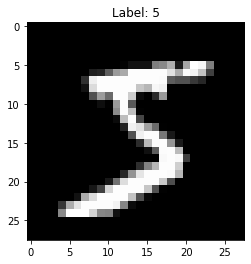

shape of x_train : (784, 50000)
shape of y_train : (10, 50000)


In [3]:
import pickle
import gzip

with gzip.open('neural-networks-and-deep-learning-master/data/mnist.pkl.gz', 'rb') as f:
    training_data, validation_data, test_data = pickle.load(f, encoding='latin1')

print('shape of raw training inputs x: ',training_data[0].shape, '\nshape of raw training labels y: ', training_data[1].shape)   # (50000, 784) (50000,)

first_image = training_data[0][0]
first_label = training_data[1][0]

# Reshape the first image to 28x28 pixels
image = first_image.reshape(28, 28)

# Display the image
plt.imshow(image, cmap='gray')
plt.title(f"Label: {first_label}")
plt.show()

# Extract labels and training images from training_data
y_labels = training_data[1]
x_train = training_data[0].T

# Extract validation data
y_labels_val = validation_data[1]
x_val = validation_data[0].T

print('shape of x_train :',x_train.shape) # (728, 50000)
d = len(y_labels)

y_train = labels_to_onehot(y_labels)
y_val = labels_to_onehot(y_labels_val)

print('shape of y_train :',y_train.shape) # (728, 50000)

# Organize training data
train_data = (x_train, y_train)
val_data = (x_val, y_val)

In [16]:
spec = [784, 30, 10]
act, del_act = [ReLU], [del_ReLU]

net = network(spec, activation=act, del_activation=del_act) 

# Compute initial accuracy of the network
print('initial accuracy', compute_accuracy(net, x_train, train_data[1]))

initial accuracy 0.189624


Modify the training loop 

In [26]:
def train_dropout(NN, train_data, val_data, epochs=20, minibatch_size=50, eta=0.1, verbose=True, loss="CE", lam=0, p_drop=0):
    '''
    Training function for a single layer using SGD. Must include a test/train split. Performs accuracies and loss calculations 
    after each epoch. Returns a NN with updated parameters and arrays containing train and test cost and accuracies.

    - L is a layer as defined above. Initial weights and biases already initialized.
    - training_data is 
    - epochs is the number of times that the training loop will visit the full training set 
    - minibatch_size is the size of the minibatch. *Same batching every epoch* TO DO: randomize batches
    - eta is the learning rate
    - verbose is a boolean indicating the desire of outputing intermediate loss calculations after each epoch
    - loss is a string indicating the loss that is used for training
    - lam is the L2 regularization parameter
    - p_drop is the proportion of hidden layer neurons to be dropped at each mini-batch 

    '''
    # Compute initial training loss
    loss0 = NN.CE_loss(train_data)
    train_losses = np.zeros(epochs)
    val_losses = np.zeros(epochs)
    train_accuracies = np.zeros(epochs)
    val_accuracies = np.zeros(epochs)
    print('Initial Training Loss', loss0)

    x_train = train_data[0]
    y_train = train_data[1]

    # Compute number of minibatches
    d_train = x_train.shape[1]
    n_batches = int(d_train / minibatch_size)
    
    for e in tqdm(range(epochs)):

        np.random.seed(42)
        # Shuffle training data
        idx = np.random.permutation(d_train)

        x_train = x_train[:, idx]
        y_train = y_train[:, idx]

        for n in range(n_batches):

            # Organize batch's training samples for SGD
            # Edge case: last batch may not be big enough. Avoid slicing error
            if n == n_batches - 1:
                x_batch = x_train[:, n * minibatch_size :]
                y_batch = y_train[:, n * minibatch_size :]
            else:
                x_batch = x_train[:, n * minibatch_size : (n+1) * minibatch_size]
                y_batch = y_train[:, n * minibatch_size: (n+1) * minibatch_size]

            data_batch = (x_batch, y_batch)

            # Iterate over *hidden* layers to drop-out neurons
            NN_dropout = copy.deepcopy(NN)

            for i in range(len(NN.layers) - 1):

                # Extract number of neurons to be dropped out at this hidden layer
                n_curr = NN.layers[i].dims[0]

                # Now we need to make n_curr draws from a binomial distribution: 0 w.p. 1 - p and 1 w.p. p
                # and set selected biases to a high negative number
                idxs = np.where(np.random.binomial(1, p_drop, n_curr) == 1)[0]
                NN_dropout.layers[i].b[idxs] = -1e8 

            # Compute gradients   
            del_W, del_b = NN_dropout.backprop(data_batch, loss=loss)

            # Iterate over layers and update parameters
            for i in range(len(NN.layers)):
                
                # Extract layer gradients
                del_Wi, del_bi = del_W[i], del_b[i]
                
                # Gradient step with (optional) L2 regularization
                NN.layers[i].W = (1 - lam * eta / d_train) * NN.layers[i].W - eta * del_Wi
                NN.layers[i].b = NN.layers[i].b - eta * del_bi


        # Recompute loss at the end of the epoch
        NN_eval = copy.deepcopy(NN)
        for i in range(1, len(NN_eval.layers)):
            NN_eval.layers[i].W *= (1 - p_drop)

        train_loss = NN_eval.CE_loss(train_data)
        val_loss = NN_eval.CE_loss(val_data)
        train_losses[e] = train_loss
        val_losses[e] = val_loss

        # Compute training and validation accuracies at each epoch
        train_acc = compute_accuracy(NN_eval, x_train, onehot_to_labels(y_train))
        val_acc = compute_accuracy(NN_eval, val_data[0], onehot_to_labels(val_data[1]))
        train_accuracies[e] = train_acc
        val_accuracies[e] = val_acc

        if verbose==True:
            print('Loss at epoch e =', e, ':', train_loss)

    # At the end of training, scale the weights outgoing from hidden neurons by p_drop  
    for i in range(1, len(NN.layers)):
        NN.layers[i].W = (1 - p_drop) * NN.layers[i].W

    return NN, train_losses, val_losses, train_accuracies, val_accuracies



Combine dropout with p = 1/2 with L2 regularization and lam=25

In [24]:
net_train = copy.deepcopy(net)

# Training params
epochs = 400
eta = 0.05
lam = 25

net_train, train_loss, val_loss, train_acc, val_acc = train_dropout(net_train, (x_train[:,:1000], y_train[:,:1000]), val_data, epochs=epochs, eta=eta, lam=lam,verbose=False, p_drop=0.5)

Initial Training Loss 2.367976669161912


100%|██████████| 400/400 [01:44<00:00,  3.83it/s]


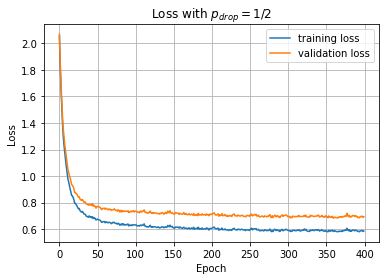

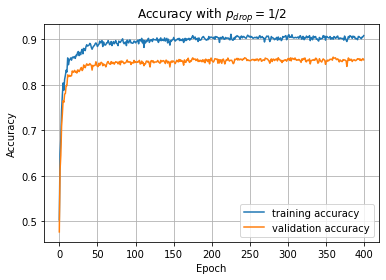

In [25]:
plot_loss(train_loss, val_loss, title='Loss with $p_{drop} = 1/2$')
plot_accuracies(train_acc, val_acc, title='Accuracy with $p_{drop} = 1/2$')

Initial Training Loss 2.367976669161912


100%|██████████| 400/400 [01:52<00:00,  3.56it/s]


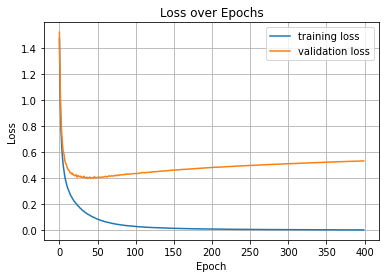

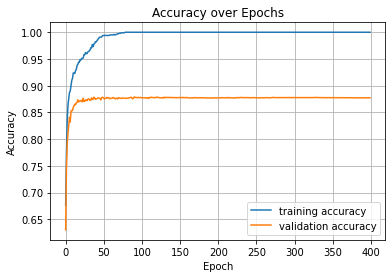

accuracy for p_drop = 0 : 0.8773
Initial Training Loss 2.367976669161912


100%|██████████| 400/400 [02:13<00:00,  2.99it/s]


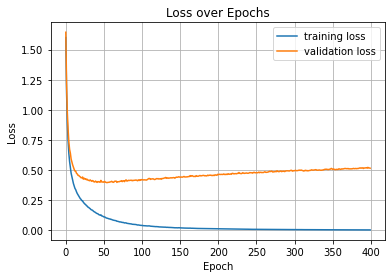

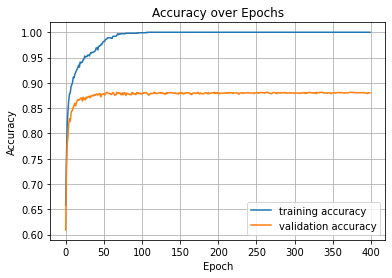

accuracy for p_drop = 0.1 : 0.8802
Initial Training Loss 2.367976669161912


100%|██████████| 400/400 [02:27<00:00,  2.71it/s]


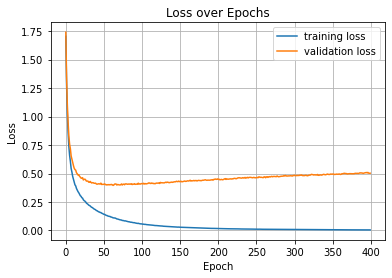

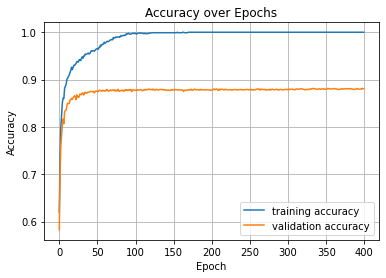

accuracy for p_drop = 0.2 : 0.8806
Initial Training Loss 2.367976669161912


100%|██████████| 400/400 [02:01<00:00,  3.30it/s]


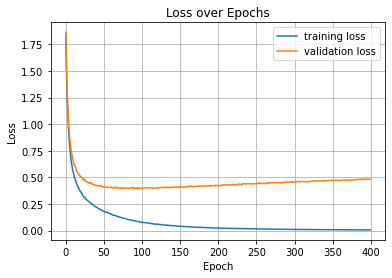

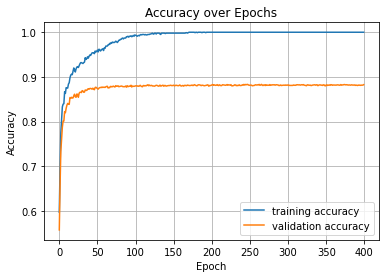

accuracy for p_drop = 0.3 : 0.8826
Initial Training Loss 2.367976669161912


100%|██████████| 400/400 [01:49<00:00,  3.66it/s]


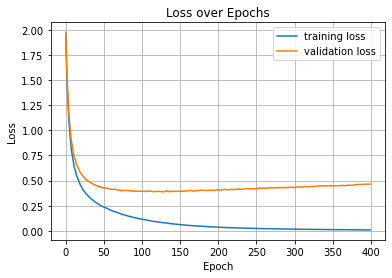

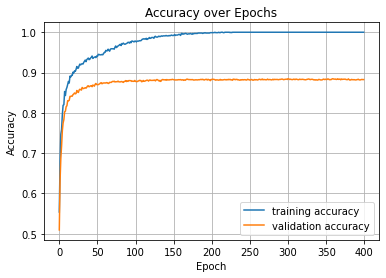

accuracy for p_drop = 0.4 : 0.8826
Initial Training Loss 2.367976669161912


100%|██████████| 400/400 [01:54<00:00,  3.50it/s]


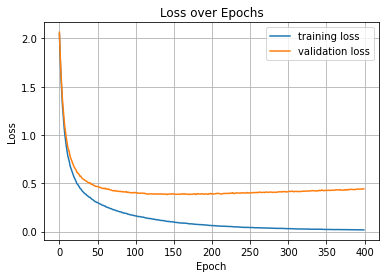

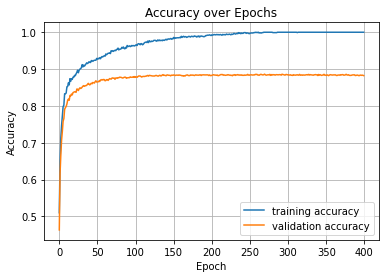

accuracy for p_drop = 0.5 : 0.8823
Initial Training Loss 2.367976669161912


100%|██████████| 400/400 [01:49<00:00,  3.64it/s]


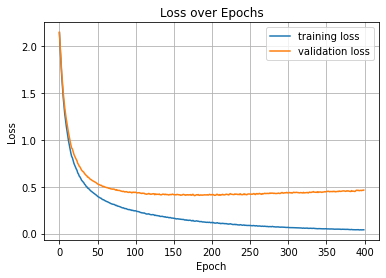

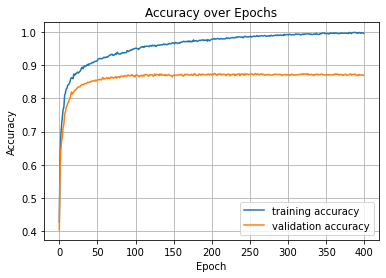

accuracy for p_drop = 0.6 : 0.8691
[0.8773 0.8802 0.8806 0.8826 0.8826 0.8823 0.8691]


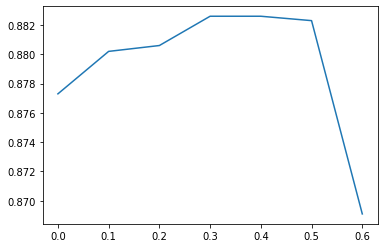

In [29]:
epochs = 400
eta = 0.05
ps = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6]
lam=0
accuracies = np.zeros(len(ps))

# Just include first 1000 samples in training
reduced_train_data = (x_train[:,:1000], y_train[:,:1000])

# Same initialization -> Same initial condition

for i in range(len(ps)):
    Ni = copy.deepcopy(net) 
    Ni, train_losses, val_losses, train_acc, val_acc = train_dropout(Ni, reduced_train_data, val_data, epochs=epochs, eta=eta, verbose=False, lam=0, p_drop=ps[i])
    plot_loss(train_losses, val_losses)
    plot_accuracies(train_acc, val_acc)
    accuracies[i] = compute_accuracy(Ni, x_val, y_labels_val)
    print('accuracy for p_drop =', ps[i], ':', accuracies[i])

print(accuracies)

plt.figure()
plt.plot(ps, accuracies)